# Homework: Fake MNIST Image Generation with Reverse-Time Diffusion

**ECE695 Stochastic Control — Parts A–D**  
A self-contained PyTorch notebook that trains a time-dependent Gaussian-noise predictor (equivalently a score estimator) and samples handwritten-digit images using a reverse-time SDE.

- **Part A:** derive and visualize the forward Ornstein–Uhlenbeck diffusion.
- **Part B:** derive denoising score matching and verify its relationship to Gaussian-noise prediction.
- **Part C:** train a small time-conditioned U-Net on MNIST; plot losses and save a checkpoint.
- **Part D:** generate fake MNIST images using reverse-time Euler–Maruyama; visualize trajectories.

**Hardware:** automatically uses CUDA if available, otherwise CPU. CPU defaults to a smaller training subset, fewer epochs, and a smaller network. Change the configuration to improve results. A fresh run downloads MNIST (internet required once); thereafter the cached dataset works offline.

**References:** Vincent (2011), *A Connection Between Score Matching and Denoising Autoencoders*; Ho, Jain & Abbeel (2020), *Denoising Diffusion Probabilistic Models*; Song et al. (2021), *Score-Based Generative Modeling through Stochastic Differential Equations*.

In [1]:
# Optional installation: uncomment and run if needed, then restart the kernel.
# %pip install torch torchvision matplotlib numpy tqdm

import os, math, random, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)
if device.type == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

DATA_DIR = Path('./data')
OUTPUT_DIR = Path('./diffusion_outputs'); OUTPUT_DIR.mkdir(exist_ok=True)
# These are defaults, not performance guarantees; increase epochs for better images.
FAST_CPU = device.type == 'cpu'
TRAIN_SUBSET = 10000 if FAST_CPU else 60000
EPOCHS = 5 if FAST_CPU else 20
BASE_CHANNELS = 16 if FAST_CPU else 32
BATCH_SIZE = 64 if FAST_CPU else 128
LEARNING_RATE = 2e-4
T_MAX = 10.0
T_MIN = 1e-3
SAMPLE_STEPS = 150 if FAST_CPU else 500
NUM_GENERATED = 100 if not FAST_CPU else 36
NUM_WORKERS = 0  # Windows/Jupyter-safe
print(dict(train_subset=TRAIN_SUBSET, epochs=EPOCHS, base_channels=BASE_CHANNELS,
           batch_size=BATCH_SIZE, sample_steps=SAMPLE_STEPS))

PyTorch: 2.11.0+cu128 | device: cuda
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
{'train_subset': 60000, 'epochs': 20, 'base_channels': 32, 'batch_size': 128, 'sample_steps': 500}


## Part A — Forward diffusion

For $X_0\sim\rho_0$, consider

$$dX_t=-\tfrac12 X_t\,dt+dW_t,\qquad 0\le t\le T.$$

The exact transition is

$$X_t=a_tX_0+\sigma_t Z,\quad a_t=e^{-t/2},\quad \sigma_t=\sqrt{1-e^{-t}},\quad Z\sim\mathcal N(0,I).$$

Hence $X_t\mid X_0=x_0\sim\mathcal N(a_tx_0,\sigma_t^2 I)$, and $X_t\Rightarrow\mathcal N(0,I)$ as $t\to\infty$. We simulate $X_t$ directly using the exact transition rather than discretizing the forward SDE.

Training images: 60000


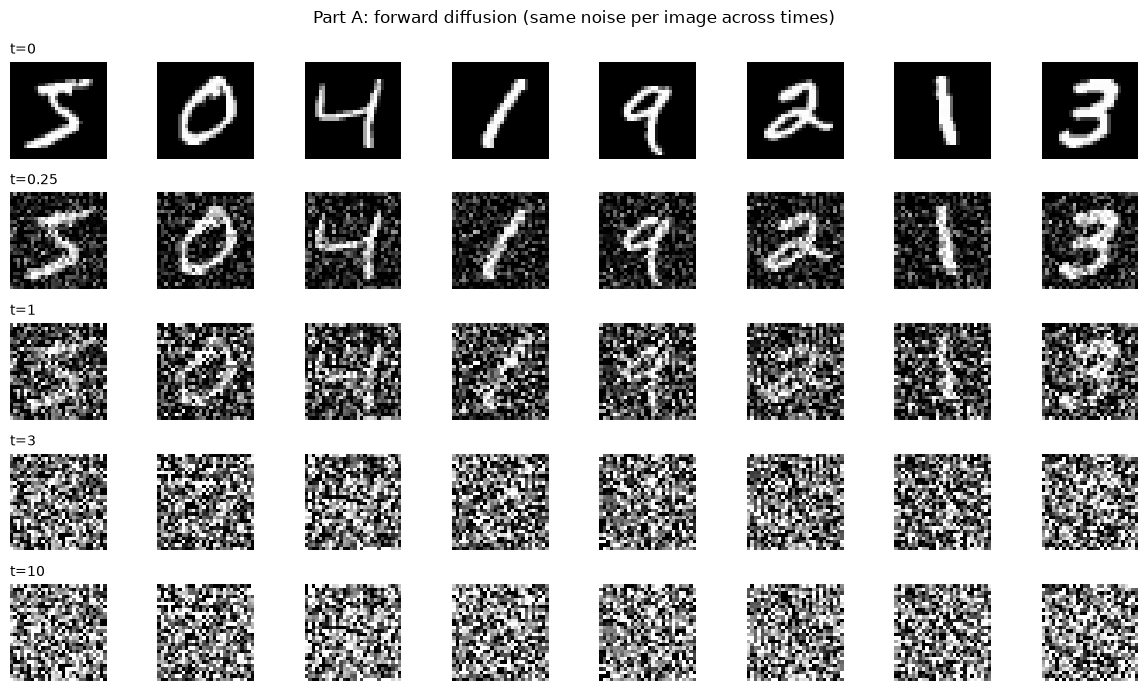

In [2]:
def alpha_sigma(t):
    """t: tensor broadcastable to image batch; returns a_t, sigma_t."""
    a = torch.exp(-0.5 * t)
    sigma = torch.sqrt(-torch.expm1(-t))  # stable 1-exp(-t)
    return a, sigma

def perturb(x0, t, noise=None):
    if noise is None: noise = torch.randn_like(x0)
    a, sigma = alpha_sigma(t)
    return a * x0 + sigma * noise, noise

transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Lambda(lambda x: 2.0*x - 1.0)])
train_full = datasets.MNIST(root=str(DATA_DIR), train=True, download=True, transform=transform)
if TRAIN_SUBSET < len(train_full):
    rng = np.random.default_rng(SEED)
    indices = rng.choice(len(train_full), TRAIN_SUBSET, replace=False).tolist()
    train_set = Subset(train_full, indices)
else: train_set = train_full
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(device.type=='cuda'), drop_last=False)
print('Training images:', len(train_set))

x0 = torch.stack([train_full[i][0] for i in range(8)]).to(device)
times = [0.0, 0.25, 1.0, 3.0, 10.0]
fig, axes = plt.subplots(len(times), 8, figsize=(12, 7))
with torch.no_grad():
    z = torch.randn_like(x0)
    for row, tval in enumerate(times):
        if tval == 0: xt = x0
        else: xt, _ = perturb(x0, torch.full((8,1,1,1), tval, device=device), z)
        for col in range(8):
            axes[row,col].imshow(xt[col,0].cpu(), cmap='gray', vmin=-1, vmax=1)
            axes[row,col].axis('off')
        axes[row,0].set_title(f't={tval:g}', loc='left', fontsize=10)
plt.suptitle('Part A: forward diffusion (same noise per image across times)')
plt.tight_layout(); plt.show()

## Part B — Denoising score matching

Write $\rho_t(x)=\int p_t(x\mid x_0)\,\rho_0(dx_0)$. Differentiation under the integral and Bayes' rule yield

$$s_t(x)=\nabla_x\log\rho_t(x)=\mathbb E[\nabla_x\log p_t(X_t\mid X_0)\mid X_t=x].$$

Because $p_t(\cdot\mid x_0)$ is Gaussian,

$$\nabla_x\log p_t(X_t\mid X_0)=-\frac{X_t-a_tX_0}{\sigma_t^2}=-\frac{Z}{\sigma_t}.$$

The conditional expectation minimizes mean-square prediction error. Thus the optimal network trained to predict $Z$ satisfies

$$\epsilon^*(x,t)=\mathbb E[Z\mid X_t=x]=-\sigma_t s_t(x).$$

We train with the **noise-prediction loss**

$$\mathcal J(\theta)=\mathbb E_{t,X_0,Z}\|\epsilon_\theta(a_tX_0+\sigma_t Z,t)-Z\|^2.$$

The score estimate is $s_\theta(x,t)=-\epsilon_\theta(x,t)/\sigma_t$. The loss is a time-weighted denoising-score-matching objective; its population minimizer is the desired score at each time. To avoid the $t=0$ singularity, training uses $t\sim U[10^{-3},10]$.

The following numerical check verifies the identity $\nabla_x\log p_t(x\mid x_0)=-Z/\sigma_t$.

In [3]:
with torch.no_grad():
    batch = x0[:4]
    t = torch.full((len(batch),1,1,1), 1.5, device=device)
    xt, z = perturb(batch, t)
    a, sigma = alpha_sigma(t)
    conditional_score_from_x = -(xt-a*batch)/sigma.square()
    conditional_score_from_z = -z/sigma
    print('Maximum conditional-score identity error:',
          (conditional_score_from_x-conditional_score_from_z).abs().max().item())

Maximum conditional-score identity error: 2.384185791015625e-07


## Part C — Train a time-conditioned U-Net

The network maps $(x_t,t)$ to a predicted noise image $\epsilon_\theta(x_t,t)$. A small U-Net captures spatial structure, while sinusoidal time embeddings make the output depend on the diffusion time. Training is unconditional: MNIST digit labels are ignored.

**CPU note:** defaults to 5 epochs on 10,000 images and a narrower U-Net; this tests the full workflow but may not produce clean digits. On CUDA, the defaults are 20 epochs on the full dataset. Increase `EPOCHS` if samples are poor.

In [4]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__(); self.dim = dim
    def forward(self, t):
        t = t.reshape(-1)
        half = self.dim // 2
        freq = torch.exp(torch.arange(half, device=t.device, dtype=t.dtype)
                         * (-math.log(10000.0) / max(half-1, 1)))
        phase = t[:,None] * freq[None,:]
        return torch.cat([phase.sin(), phase.cos()], dim=1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.norm1 = nn.GroupNorm(min(8, in_ch), in_ch)
        self.norm2 = nn.GroupNorm(min(8, out_ch), out_ch)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(emb)[:,:,None,None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class TinyUNet(nn.Module):
    def __init__(self, base=32, time_dim=64):
        super().__init__()
        self.time_mlp = nn.Sequential(SinusoidalTimeEmbedding(time_dim),
                                      nn.Linear(time_dim,time_dim), nn.SiLU(),
                                      nn.Linear(time_dim,time_dim))
        self.in_conv = nn.Conv2d(1, base, 3, padding=1)
        self.enc1 = ResBlock(base, base, time_dim)
        self.down1 = nn.Conv2d(base, base, 3, stride=2, padding=1)       # 28 -> 14
        self.enc2 = ResBlock(base, 2*base, time_dim)
        self.down2 = nn.Conv2d(2*base, 2*base, 3, stride=2, padding=1) # 14 -> 7
        self.mid = ResBlock(2*base, 2*base, time_dim)
        self.dec2 = ResBlock(4*base, 2*base, time_dim)                 # 7 -> 14
        self.dec1 = ResBlock(3*base, base, time_dim)                   # 14 -> 28
        self.out_norm = nn.GroupNorm(min(8,base),base)
        self.out_conv = nn.Conv2d(base, 1, 3, padding=1)
    def forward(self, x, t):
        emb = self.time_mlp(t)
        h0 = self.in_conv(x)
        h1 = self.enc1(h0,emb)
        h2 = self.enc2(self.down1(h1),emb)
        h3 = self.mid(self.down2(h2),emb)
        h = F.interpolate(h3, size=h2.shape[-2:], mode='nearest')
        h = self.dec2(torch.cat([h,h2],dim=1),emb)
        h = F.interpolate(h, size=h1.shape[-2:], mode='nearest')
        h = self.dec1(torch.cat([h,h1],dim=1),emb)
        return self.out_conv(F.silu(self.out_norm(h)))

model = TinyUNet(base=BASE_CHANNELS).to(device)
print('Parameters:', sum(p.numel() for p in model.parameters()))
with torch.no_grad():
    test_output = model(torch.randn(2,1,28,28,device=device), torch.ones(2,device=device))
assert test_output.shape == (2,1,28,28)
print('Output shape test passed.')

Parameters: 381921
Output shape test passed.


Epoch 1/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 01 | mean noise MSE = 0.05351 | elapsed = 0.2 min


Epoch 2/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 02 | mean noise MSE = 0.01725 | elapsed = 0.4 min


Epoch 3/20:   0%|          | 0/469 [00:00<?, ?it/s]

...

Epoch 18 | mean noise MSE = 0.01001 | elapsed = 4.3 min


Epoch 19/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 19 | mean noise MSE = 0.00998 | elapsed = 4.5 min


Epoch 20/20:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 20 | mean noise MSE = 0.00990 | elapsed = 4.7 min


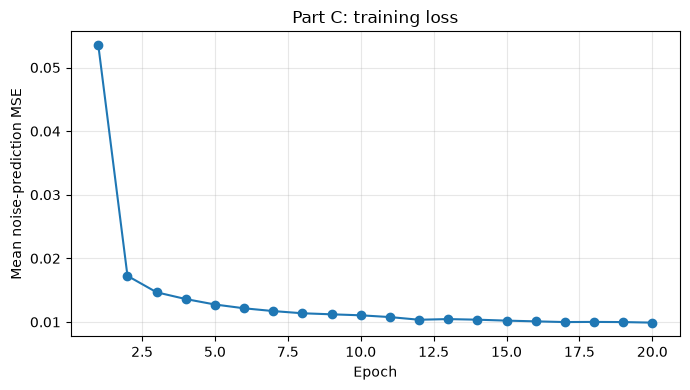

Checkpoint: C:\Users\space\Documents\Git\MNIST-diffusion-model\diffusion_outputs\mnist_ou_unet_base32.pt


In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
checkpoint_path = OUTPUT_DIR / f'mnist_ou_unet_base{BASE_CHANNELS}.pt'
# Set RESUME=True to load a previously saved checkpoint for the same architecture.
RESUME = False
history = []
if RESUME and checkpoint_path.exists():
    state = torch.load(checkpoint_path, map_location=device, weights_only=False)
    model.load_state_dict(state['model']); optimizer.load_state_dict(state['optimizer'])
    history = list(state.get('loss_history', []))
    print('Resumed from', checkpoint_path)

start = time.time()
for epoch in range(EPOCHS):
    model.train(); running = 0.0; count = 0
    bar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{EPOCHS}', leave=False)
    for images, _labels in bar:
        images = images.to(device, non_blocking=True)
        t = T_MIN + (T_MAX-T_MIN)*torch.rand(images.size(0), device=device)
        noisy, z = perturb(images, t[:,None,None,None])
        pred = model(noisy, t)
        loss = F.mse_loss(pred, z)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        running += loss.item()*images.size(0); count += images.size(0)
        bar.set_postfix(loss=f'{loss.item():.3f}')
    mean_loss = running/count
    history.append(mean_loss)
    print(f'Epoch {epoch+1:02d} | mean noise MSE = {mean_loss:.5f} | elapsed = {(time.time()-start)/60:.1f} min')
    torch.save({'model':model.state_dict(), 'optimizer':optimizer.state_dict(),
                'loss_history':history, 'base_channels':BASE_CHANNELS}, checkpoint_path)

plt.figure(figsize=(7,4)); plt.plot(np.arange(1,len(history)+1),history,'o-')
plt.xlabel('Epoch'); plt.ylabel('Mean noise-prediction MSE'); plt.title('Part C: training loss')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print('Checkpoint:', checkpoint_path.resolve())

## Part D — Reverse-time Euler–Maruyama image generation

The forward drift is $f(x,t)=-\tfrac12x$ and the diffusion coefficient is $g=1$. The reverse-time SDE, **written with the original time variable decreasing**, is

$$dX_t=[-\tfrac12X_t-s_t(X_t)]\,dt+dW_t^*.$$

For $h>0$, Euler–Maruyama integrates from $t$ to $t-h$:

$$X_{t-h}=X_t+h[\tfrac12X_t+s_\theta(X_t,t)]+\sqrt{h}\,Z,$$

where $Z\sim\mathcal N(0,I)$ is newly sampled at each step. Initialize $X_T\sim\mathcal N(0,I)$. We stop at $t=10^{-3}$ rather than zero to avoid division by zero in $s_\theta=-\epsilon_\theta/\sigma_t$. The terminal prior $\mathcal N(0,I)$ is an approximation to $\rho_T$ (excellent for $T=10$).

**Important:** A CPU run with few training epochs is primarily a correctness demonstration; high-quality samples may require longer training.

Reverse SDE sampling:   0%|          | 0/500 [00:00<?, ?it/s]

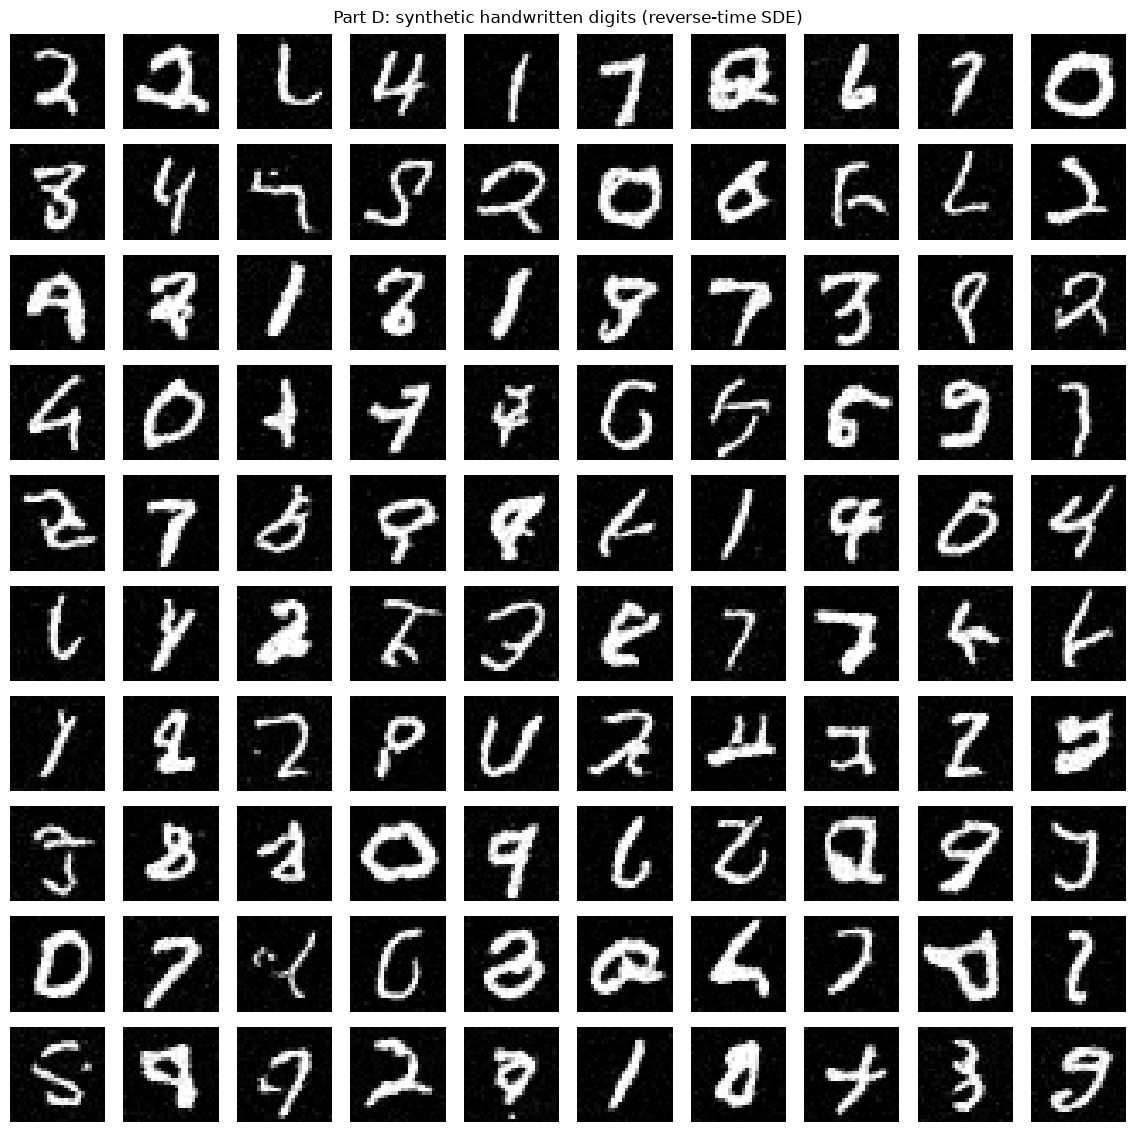

In [6]:
@torch.no_grad()
def sample_reverse_sde(model, num_images=36, steps=500, snapshot_times=(10,5,2,1,0.25,0.001)):
    model.eval()
    x = torch.randn(num_images,1,28,28,device=device)
    grid = torch.linspace(T_MAX, T_MIN, steps+1,device=device)
    snapshots = {'t=10.000':x[:8].detach().cpu().clone()}
    requested = sorted(snapshot_times, reverse=True)
    saved = set()
    for k in tqdm(range(steps),desc='Reverse SDE sampling',leave=False):
        t = grid[k]; next_t = grid[k+1]; h = t-next_t
        t_batch = torch.full((num_images,),float(t),device=device)
        _, sigma = alpha_sigma(t)
        score = -model(x,t_batch)/sigma
        noise = torch.randn_like(x) if k < steps-1 else torch.zeros_like(x)
        x = x + h*(0.5*x + score) + torch.sqrt(h)*noise
        for target in requested:
            if target not in saved and float(next_t) <= target:
                snapshots[f't={float(next_t):.3f}'] = x[:8].detach().cpu().clone()
                saved.add(target)
    return x.detach().cpu(), snapshots

generated, snapshots = sample_reverse_sde(model, num_images=NUM_GENERATED, steps=SAMPLE_STEPS)

def show_grid(images, title, columns=10, save_path=None):
    images = images.clamp(-1,1)
    n = len(images); rows = math.ceil(n/columns)
    fig, axes = plt.subplots(rows,columns,figsize=(columns*1.15,rows*1.15),squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < n: ax.imshow(images[i,0].numpy(),cmap='gray',vmin=-1,vmax=1)
    fig.suptitle(title); plt.tight_layout()
    if save_path: fig.savefig(save_path,dpi=160,bbox_inches='tight')
    plt.show()

show_grid(generated, 'Part D: synthetic handwritten digits (reverse-time SDE)',
          columns=10 if NUM_GENERATED>=100 else 6,
          save_path=OUTPUT_DIR/'generated_digits.png')

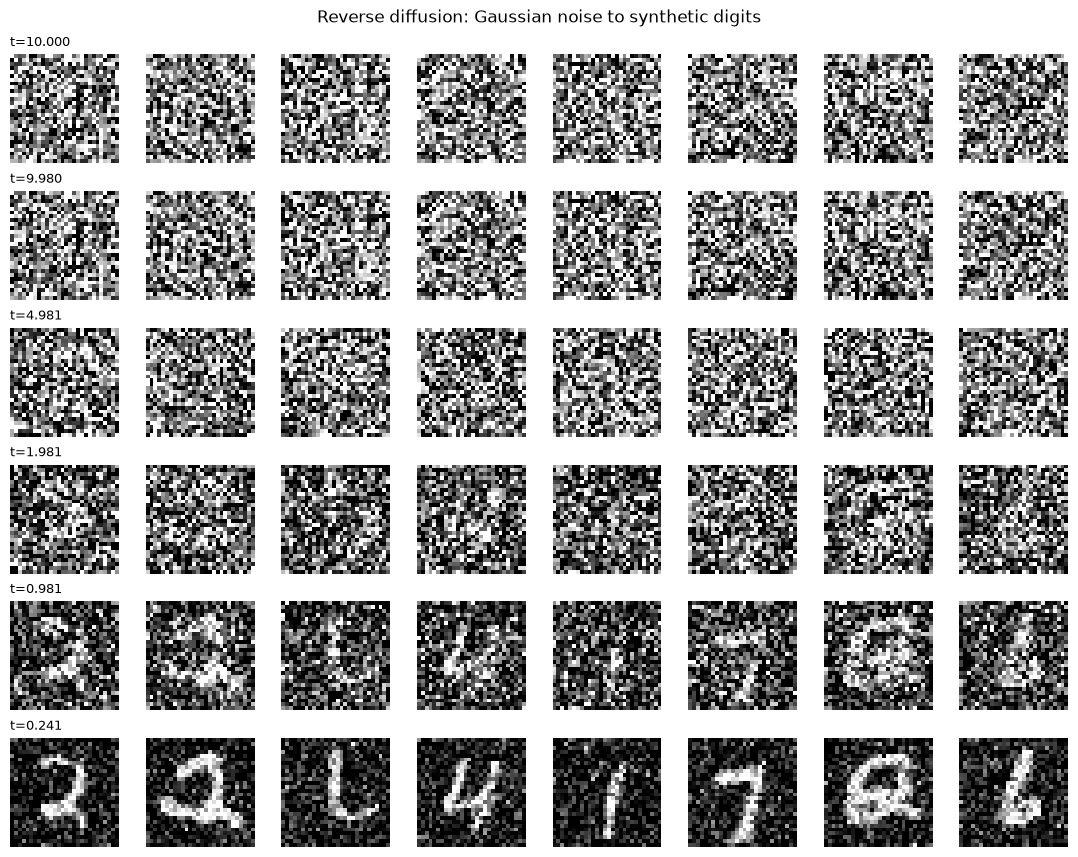

In [7]:
# The columns show independent sample paths; rows show their intermediate states.
keys = list(snapshots.keys())
fig, axes = plt.subplots(len(keys),8,figsize=(11,1.45*len(keys)),squeeze=False)
for row,key in enumerate(keys):
    images = snapshots[key].clamp(-1,1)
    for col in range(8):
        axes[row,col].imshow(images[col,0].numpy(),cmap='gray',vmin=-1,vmax=1)
        axes[row,col].axis('off')
    axes[row,0].set_title(key,loc='left',fontsize=9)
fig.suptitle('Reverse diffusion: Gaussian noise to synthetic digits')
plt.tight_layout(); fig.savefig(OUTPUT_DIR/'reverse_trajectories.png',dpi=160,bbox_inches='tight'); plt.show()

## Discussion questions / submission checklist

1. **Part A:** Derive the conditional mean and covariance of $X_t\mid X_0$; explain why $\rho_T\approx\mathcal N(0,I)$.
2. **Part B:** Prove $s_t(x)=\mathbb E[-Z/\sigma_t\mid X_t=x]$ and explain why the noise-prediction MSE is a valid training objective. Distinguish fixed-$t$ equivalence from time weighting.
3. **Part C:** Submit the training-loss plot and describe the architecture, epochs, subset size, device, and elapsed time.
4. **Part D:** Submit a grid of synthetic images and intermediate reverse-diffusion states; explain the signs in the Euler–Maruyama update.
5. **Optional:** Compare $N=100,250,500,1000$ sampling steps; discuss numerical error versus network approximation error.

**Files saved:** `diffusion_outputs/mnist_ou_unet_base*.pt`, `generated_digits.png`, and `reverse_trajectories.png`.

**Academic context:** these are synthetic handwritten digits, not impersonations or images of real people. The notebook trains from scratch and uses no pretrained model.